<a href="https://colab.research.google.com/github/natsakh/ElectromagneticNets/blob/main/1_abrupt_temporal_transition_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Abrupt Temporal Transition Benchmark

This notebook reproduces the abrupt temporal-transition results reported in
the paper *Physics-Informed Neural Networks for Electromagnetic Wave
Propagation in Time-Varying Media: Analytical Benchmarks for Initial-Value
Problems*.

Running the notebook from top to bottom trains the global tanh, global SIREN,
and sequential time-marching SIREN PINNs for both refractive-index contrasts,
reports the five-run statistics collected in Table 2, and generates Figures 2
and 3. The analytical solution is used only to evaluate the trained networks;
no labeled field values are used during training.


In [ ]:
from pathlib import Path
import csv
import json
import time
import random
import math

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from datetime import datetime

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

from google.colab import drive
drive.mount("/content/drive")

timestamp = datetime.now().strftime("%Y%m%d_%H%M")
EXPERIMENT = f"abrupt_temporal_transition_{timestamp}"

BASE_DIR = Path("/content/drive/MyDrive/TimeVaryingMedia")
OUTPUT_DIR = BASE_DIR / EXPERIMENT

MODELS_DIR = OUTPUT_DIR / "models"
LOSS_DIR = OUTPUT_DIR / "loss_history"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
TABLES_DIR = OUTPUT_DIR / "tables"

for directory in [OUTPUT_DIR, MODELS_DIR, LOSS_DIR, PREDICTIONS_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Saving to:", OUTPUT_DIR)


device: cuda
Mounted at /content/drive
Saving to: /content/drive/MyDrive/TimeVaryingMedia/abrupt_temporal_transition_20260829_0853


## Problem definition

For $t>0$, the separated complex amplitudes satisfy
$$
\frac{dD}{dt}=\frac{i k_1}{\mu_0}B,
\qquad
\frac{dB}{dt}=\frac{i k_1}{\varepsilon_0 n_2^2}D.
$$

At $t=0$, both $D$ and $B$ are continuous.

In [ ]:
# Physical parameters
n1 = 1.5
N2_VALUES = [1.55, 1.8]
omega1 = 2 * np.pi
E0 = 1.0

epsilon0 = 1.0
mu0 = 1.0
c = 1.0

T0 = 2 * np.pi / omega1
k1 = n1 * omega1 / c

D0 = epsilon0 * n1**2 * E0
H0 = n1 / (mu0 * c) * E0
B0 = mu0 * H0


## Experiment configuration

The settings below reproduce Table 1 and the abrupt-transition cases used in
Figures 2–3 and Table 2. The two refractive-index contrasts are evaluated with
the same network architecture and training protocol.


In [ ]:
# Temporal windows used for each method
TAU_MAX_BY_CONFIG = {
    "tanh": [3.0, 4.0, 5.0],
    "siren": [10.0, 20.0, 21.0, 22.0],
    "siren_marching": [40.0, 60.0],
}
RUN_CONFIGS = list(TAU_MAX_BY_CONFIG)
MARCHING_STEP = 20.0

# Five independent runs reported as mean ± standard deviation
SEEDS = [42, 43, 44, 45, 46]

# Table 1: selected PINN configuration
N_COLLOCATION_PER_PERIOD = 500
N_EVAL_PER_PERIOD = 500
HIDDEN_LAYERS = 4
HIDDEN_DIM = 64
ADAM_EPOCHS = 10_000
ADAM_LEARNING_RATE = 1e-3
LBFGS_MAX_ITER = 1_000
IC_WEIGHT = 20.0
GRAD_CLIP = 1.0

# L-BFGS numerical settings
LBFGS_HISTORY_SIZE = 100
LBFGS_TOLERANCE_GRAD = 1e-9
LBFGS_TOLERANCE_CHANGE = 1e-12
LBFGS_LINE_SEARCH_FN = "strong_wolfe"

# Loss histories are sampled on an independent uniform evaluation grid.
EVAL_LOSS_EVERY = 100
LBFGS_EVAL_LOSS_EVERY = 100

ARCHITECTURE = f"{HIDDEN_LAYERS}x{HIDDEN_DIM}"
SIREN_OMEGA = omega1  # known incident frequency, never the shifted frequency

CONFIG = {
    "benchmark": "abrupt_temporal_transition",
    "n1": n1,
    "n2_values": N2_VALUES,
    "tau_max_by_config": TAU_MAX_BY_CONFIG,
    "marching_step": MARCHING_STEP,
    "seeds": SEEDS,
    "temporal_normalization": "t/T0",
    "architecture": ARCHITECTURE,
    "activation": "tanh or sine",
    "n_collocation_per_period": N_COLLOCATION_PER_PERIOD,
    "n_evaluation_per_period": N_EVAL_PER_PERIOD,
    "adam_epochs_per_model": ADAM_EPOCHS,
    "adam_learning_rate": ADAM_LEARNING_RATE,
    "lbfgs_max_iter_per_model": LBFGS_MAX_ITER,
    "ic_weight": IC_WEIGHT,
    "gradient_clip": GRAD_CLIP,
    "siren_omega": float(SIREN_OMEGA),
}

with (OUTPUT_DIR / "config.json").open("w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

print(json.dumps(CONFIG, indent=2))


{
  "benchmark": "abrupt_temporal_transition",
  "n1": 1.5,
  "n2_values": [
    1.55,
    1.8
  ],
  "tau_max_by_config": {
    "tanh": [
      3.0,
      4.0,
      5.0
    ],
    "siren": [
      10.0,
      20.0,
      21.0,
      22.0
    ],
    "siren_marching": [
      40.0,
      60.0
    ]
  },
  "marching_step": 20.0,
  "seeds": [
    42,
    43,
    44,
    45,
    46
  ],
  "temporal_normalization": "t/T0",
  "architecture": "4x64",
  "activation": "tanh or sine",
  "n_collocation_per_period": 500,
  "n_evaluation_per_period": 500,
  "adam_epochs_per_model": 10000,
  "adam_learning_rate": 0.001,
  "lbfgs_max_iter_per_model": 1000,
  "ic_weight": 20.0,
  "gradient_clip": 1.0,
  "siren_omega": 6.283185307179586
}


## Reproducibility

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

## PINN model

The model has four real outputs, representing
$\operatorname{Re}D$, $\operatorname{Im}D$, $\operatorname{Re}B$, and
$\operatorname{Im}B$. The global tanh and SIREN cases use the same depth and
width; the SIREN variant replaces tanh with sinusoidal activations and the
corresponding initialization.


In [ ]:
class TanhPINN(nn.Module):
    def __init__(self, hidden_dim=64, hidden_layers=4):
        super().__init__()

        layers = [nn.Linear(1, hidden_dim), nn.Tanh()]
        for _ in range(hidden_layers - 1):
            layers.extend([nn.Linear(hidden_dim, hidden_dim), nn.Tanh()])

        layers.append(nn.Linear(hidden_dim, 4))
        self.net = nn.Sequential(*layers)

    def forward(self, t):
        return self.net(t)


class SineLayer(nn.Module):
    def __init__(
        self,
        in_features,
        out_features,
        omega_0,
        is_first=False,
    ):
        super().__init__()
        self.in_features = in_features
        self.omega_0 = float(omega_0)
        self.linear = nn.Linear(in_features, out_features)
        self.reset_parameters(is_first=is_first)

    def reset_parameters(self, is_first):
        with torch.no_grad():
            if is_first:
                bound = 1.0 / self.in_features
            else:
                bound = math.sqrt(6.0 / self.in_features) / self.omega_0
            self.linear.weight.uniform_(-bound, bound)
            self.linear.bias.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))


class SirenPINN(nn.Module):
    def __init__(
        self,
        hidden_dim=64,
        hidden_layers=4,
        omega_0=2 * math.pi,
    ):
        super().__init__()

        layers = [
            SineLayer(
                1,
                hidden_dim,
                omega_0=omega_0,
                is_first=True,
            )
        ]
        for _ in range(hidden_layers - 1):
            layers.append(
                SineLayer(
                    hidden_dim,
                    hidden_dim,
                    omega_0=omega_0,
                    is_first=False,
                )
            )

        self.hidden = nn.Sequential(*layers)
        self.output = nn.Linear(hidden_dim, 4)

        with torch.no_grad():
            bound = math.sqrt(6.0 / hidden_dim) / float(omega_0)
            self.output.weight.uniform_(-bound, bound)
            self.output.bias.uniform_(-bound, bound)

    def forward(self, t):
        return self.output(self.hidden(t))


def build_model(activation):
    if activation == "tanh":
        return TanhPINN(
            hidden_dim=HIDDEN_DIM,
            hidden_layers=HIDDEN_LAYERS,
        )

    if activation == "siren":
        return SirenPINN(
            hidden_dim=HIDDEN_DIM,
            hidden_layers=HIDDEN_LAYERS,
            omega_0=SIREN_OMEGA,
        )

    raise ValueError(f"Unknown activation: {activation}")


def make_intervals(tau_max, marching_step=None):
    if marching_step is None:
        return [(0.0, float(tau_max))]

    boundaries = [0.0]
    while boundaries[-1] < tau_max:
        boundaries.append(min(boundaries[-1] + marching_step, tau_max))

    return list(zip(boundaries[:-1], boundaries[1:]))


## Losses

In [ ]:
def gradients(y, x):
    return torch.autograd.grad(
        y, x, torch.ones_like(y), create_graph=True
    )[0]


def physics_loss(model, t):
    fields = model(t)

    dR = fields[:, 0:1]
    dI = fields[:, 1:2]
    bR = fields[:, 2:3]
    bI = fields[:, 3:4]

    dR_t = gradients(dR, t)
    dI_t = gradients(dI, t)
    bR_t = gradients(bR, t)
    bI_t = gradients(bI, t)

    residual_dR = dR_t + k1 / mu0 * bI
    residual_dI = dI_t - k1 / mu0 * bR
    residual_bR = bR_t + k1 / (epsilon0 * n2**2) * dI
    residual_bI = bI_t - k1 / (epsilon0 * n2**2) * dR

    return torch.mean(
        residual_dR**2
        + residual_dI**2
        + residual_bR**2
        + residual_bI**2
    )


def initial_loss(model, t_left, target_fields):
    predicted_fields = model(t_left)
    return torch.mean((predicted_fields - target_fields) ** 2)


def physical_initial_fields():
    return torch.tensor(
        [[D0, 0.0, B0, 0.0]],
        dtype=torch.float32,
        device=device,
    )

## Training

In [ ]:
def make_training_tensors(t_left, t_right, n_collocation_per_period, seed):
    """Create collocation and initial points in the local coordinate s.

    The physical segment is [t_left, t_right], while the neural network input is

        s = tau - t_left in [0, t_right - t_left].
    """
    set_seed(seed)

    interval_length = t_right - t_left
    N_f = max(1, int(n_collocation_per_period * interval_length))

    s_f_train_np = np.random.rand(N_f, 1) * interval_length
    s_f_train = torch.tensor(
        s_f_train_np,
        dtype=torch.float32,
        device=device,
        requires_grad=True,
    )

    s_left = torch.tensor(
        [[0.0]],
        dtype=torch.float32,
        device=device,
        requires_grad=True,
    )

    return s_f_train, s_left


def evaluate_losses(
    model,
    s_f_train,
    s_left,
    target_fields,
    t_left,
    t_right,
):
    interval_length = t_right - t_left

    n_eval = int(N_EVAL_PER_PERIOD * interval_length) + 1
    s_f_val = torch.linspace(
        0.0,
        interval_length,
        n_eval,
        device=device,
    ).reshape(-1, 1)
    s_f_val.requires_grad_(True)

    loss_phys_train = physics_loss(model, s_f_train)
    loss_phys_val = physics_loss(model, s_f_val)
    loss_ic = initial_loss(model, s_left, target_fields)
    loss_total = loss_phys_train + IC_WEIGHT * loss_ic

    return {
        "total_loss": loss_total.item(),
        "physics_train_loss": loss_phys_train.item(),
        "physics_eval_loss": loss_phys_val.item(),
        "initial_loss": loss_ic.item(),
    }


def train_adam(
    model,
    s_f_train,
    s_left,
    target_fields,
    epochs,
    t_left,
    t_right,
    segment_id,
):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=ADAM_LEARNING_RATE,
    )

    loss_history = []
    training_time_s = 0.0

    # Fixed uniform grid used only to monitor the PDE residual.
    # These points are never used by the optimizer.
    interval_length = t_right - t_left
    n_eval = int(N_EVAL_PER_PERIOD * interval_length) + 1
    s_f_eval = torch.linspace(
        0.0, interval_length, n_eval, device=device
    ).reshape(-1, 1)
    s_f_eval.requires_grad_(True)

    for epoch in range(epochs):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        step_start = time.perf_counter()

        optimizer.zero_grad()
        loss_phys_train = physics_loss(model, s_f_train)
        loss_ic = initial_loss(model, s_left, target_fields)
        loss_total = loss_phys_train + IC_WEIGHT * loss_ic

        loss_total.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP,
        )
        optimizer.step()

        if torch.cuda.is_available():
            torch.cuda.synchronize()
        training_time_s += time.perf_counter() - step_start

        # Evaluation is deliberately performed after the timed block.
        # It therefore does not change the reported training time.
        if (epoch == 0) or ((epoch + 1) % EVAL_LOSS_EVERY == 0):
            loss_phys_eval = physics_loss(model, s_f_eval).item()
        else:
            loss_phys_eval = np.nan

        loss_history.append({
            "segment": segment_id,
            "t_left": t_left,
            "t_right": t_right,
            "local_t_left": 0.0,
            "local_t_right": t_right - t_left,
            "stage": "Adam",
            "step": epoch + 1,
            "adam_epoch": epoch + 1,
            "lbfgs_iteration": 0,
            "function_evaluation": 0,
            "total_loss": loss_total.item(),
            "physics_train_loss": loss_phys_train.item(),
            "physics_eval_loss": loss_phys_eval,
            "initial_loss": loss_ic.item(),
        })

    final_losses = evaluate_losses(
        model,
        s_f_train,
        s_left,
        target_fields,
        t_left,
        t_right,
    )
    loss_history.append({
        "segment": segment_id,
        "t_left": t_left,
        "t_right": t_right,
        "local_t_left": 0.0,
        "local_t_right": t_right - t_left,
        "stage": "Adam final",
        "step": epochs,
        "adam_epoch": epochs,
        "lbfgs_iteration": 0,
        "function_evaluation": 0,
        **final_losses,
    })

    return loss_history, training_time_s


def train_lbfgs(
    model,
    s_f_train,
    s_left,
    target_fields,
    t_left,
    t_right,
    segment_id,
):
    optimizer = torch.optim.LBFGS(
        model.parameters(),
        max_iter=LBFGS_MAX_ITER,
        history_size=LBFGS_HISTORY_SIZE,
        tolerance_grad=LBFGS_TOLERANCE_GRAD,
        tolerance_change=LBFGS_TOLERANCE_CHANGE,
        line_search_fn=LBFGS_LINE_SEARCH_FN,
    )

    raw_history = []
    function_evaluations = 0
    evaluation_time_s = 0.0

    interval_length = t_right - t_left
    n_eval = int(N_EVAL_PER_PERIOD * interval_length) + 1
    s_f_eval = torch.linspace(
        0.0, interval_length, n_eval, device=device
    ).reshape(-1, 1)
    s_f_eval.requires_grad_(True)

    def closure():
        nonlocal function_evaluations, evaluation_time_s
        optimizer.zero_grad()

        loss_phys_train = physics_loss(model, s_f_train)
        loss_ic = initial_loss(model, s_left, target_fields)
        loss_total = loss_phys_train + IC_WEIGHT * loss_ic
        loss_total.backward()

        function_evaluations += 1

        if (
            function_evaluations == 1
            or function_evaluations % LBFGS_EVAL_LOSS_EVERY == 0
        ):
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            eval_start = time.perf_counter()
            loss_phys_eval = physics_loss(model, s_f_eval).item()
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            evaluation_time_s += time.perf_counter() - eval_start
        else:
            loss_phys_eval = np.nan

        raw_history.append((
            function_evaluations,
            loss_total.detach(),
            loss_phys_train.detach(),
            loss_ic.detach(),
            loss_phys_eval,
        ))
        return loss_total

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    training_start = time.perf_counter()

    optimizer.step(closure)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    training_time_s = (
        time.perf_counter() - training_start - evaluation_time_s
    )

    state = optimizer.state.get(optimizer._params[0], {})
    lbfgs_iterations = int(state.get("n_iter", 0))
    recorded_function_evaluations = int(
        state.get("func_evals", function_evaluations)
    )

    closure_history = []
    for (
        function_evaluation,
        loss_total,
        loss_phys_train,
        loss_ic,
        loss_phys_eval,
    ) in raw_history:
        closure_history.append({
            "segment": segment_id,
            "t_left": t_left,
            "t_right": t_right,
            "local_t_left": 0.0,
            "local_t_right": t_right - t_left,
            "stage": "L-BFGS",
            "step": function_evaluation,
            "adam_epoch": ADAM_EPOCHS,
            "lbfgs_iteration": np.nan,
            "function_evaluation": function_evaluation,
            "total_loss": loss_total.item(),
            "physics_train_loss": loss_phys_train.item(),
            "physics_eval_loss": loss_phys_eval,
            "initial_loss": loss_ic.item(),
        })

    final_losses = evaluate_losses(
        model,
        s_f_train,
        s_left,
        target_fields,
        t_left,
        t_right,
    )
    closure_history.append({
        "segment": segment_id,
        "t_left": t_left,
        "t_right": t_right,
        "local_t_left": 0.0,
        "local_t_right": t_right - t_left,
        "stage": "L-BFGS final",
        "step": function_evaluations + 1,
        "adam_epoch": ADAM_EPOCHS,
        "lbfgs_iteration": lbfgs_iterations,
        "function_evaluation": recorded_function_evaluations,
        **final_losses,
    })

    return (
        closure_history,
        training_time_s,
        lbfgs_iterations,
        recorded_function_evaluations,
    )


## Analytical reference solution

The analytical solution provides the reference fields used to calculate the
relative errors and produce the comparison plots. It is not used in the PINN
loss or during training.


In [ ]:
def exact_fields(tau):
    A1 = epsilon0 * E0 * n1 * (n1 + n2) / 2
    A2 = epsilon0 * E0 * n1 * (n1 - n2) / 2

    d_true = (
        A1 * np.exp(1j * omega2 * tau)
        + A2 * np.exp(-1j * omega2 * tau)
    )

    b_true = (
        A1 * np.exp(1j * omega2 * tau)
        - A2 * np.exp(-1j * omega2 * tau)
    ) / (epsilon0 * n2 * c)

    return d_true, b_true


def relative_l2(pred, true):
    return np.linalg.norm(pred - true) / np.linalg.norm(true)


def normalized_max_abs_error(pred, true):
    return np.max(np.abs(pred - true)) / np.max(np.abs(true))


def predict_piecewise(models, intervals, tau):
    fields = np.empty((len(tau), 4), dtype=np.float32)

    for segment_id, ((t_left, t_right), model) in enumerate(
        zip(intervals, models)
    ):
        if segment_id < len(intervals) - 1:
            mask = (tau >= t_left) & (tau < t_right)
        else:
            mask = (tau >= t_left) & (tau <= t_right)

        # Convert global time to the local coordinate used by this model.
        s_segment_np = (tau[mask] - t_left).reshape(-1, 1)
        s_segment = torch.tensor(
            s_segment_np,
            dtype=torch.float32,
            device=device,
        )

        with torch.no_grad():
            fields[mask] = model(s_segment).cpu().numpy()

    return fields

def evaluate_models(models, intervals, tau_max):
    n_eval = int(N_EVAL_PER_PERIOD * tau_max) + 1
    tau = np.linspace(0.0, tau_max, n_eval)
    fields = predict_piecewise(models, intervals, tau)

    d_pred = fields[:, 0] + 1j * fields[:, 1]
    b_pred = fields[:, 2] + 1j * fields[:, 3]
    d_true, b_true = exact_fields(tau)

    metrics = {
        "relative_l2_D": relative_l2(d_pred, d_true),
        "relative_l2_B": relative_l2(b_pred, b_true),
        "max_normalized_abs_D": normalized_max_abs_error(d_pred, d_true),
        "max_normalized_abs_B": normalized_max_abs_error(b_pred, b_true),
    }

    prediction_rows = []
    for i, tau_value in enumerate(tau):
        prediction_rows.append({
            "tau": tau_value,
            "D_pred_real": d_pred[i].real,
            "D_pred_imag": d_pred[i].imag,
            "D_true_real": d_true[i].real,
            "D_true_imag": d_true[i].imag,
            "D_abs_error": abs(d_pred[i] - d_true[i]),
            "B_pred_real": b_pred[i].real,
            "B_pred_imag": b_pred[i].imag,
            "B_true_real": b_true[i].real,
            "B_true_imag": b_true[i].imag,
            "B_abs_error": abs(b_pred[i] - b_true[i]),
        })

    return metrics, prediction_rows

## CSV utilities

In [ ]:
def save_rows(path, rows):
    if not rows:
        return

    with Path(path).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)

## Run selected configurations

Loop order: configuration → total temporal window → seed → marching segment.

For a global configuration there is one interval, `[0, tau_max]`. For a marching
configuration, each segment has a newly initialized model. Its left-boundary
target is detached from the preceding model, so only the current segment is
optimized.

In [ ]:
run_metrics = []

for n2 in N2_VALUES:
    omega2 = n1 / n2 * omega1
    k1 = n1 * omega1 / c

    print(f"\nRefractive-index transition: n1={n1:g} -> n2={n2:g}")

    for config_name in RUN_CONFIGS:
        activation = "siren" if config_name.startswith("siren") else "tanh"
        marching = config_name == "siren_marching"
        marching_step = MARCHING_STEP if marching else None

        for tau_max in TAU_MAX_BY_CONFIG[config_name]:
            intervals = make_intervals(tau_max, marching_step)

            for seed in SEEDS:
                print(
                    f"\n{config_name}: Tmax/T0={tau_max:g}, "
                    f"seed={seed}, models={len(intervals)}"
                )

                models = []
                model_states = []
                combined_history = []
                target_fields = physical_initial_fields()
                adam_time_total_s = 0.0
                lbfgs_time_total_s = 0.0
                lbfgs_iterations_total = 0
                lbfgs_function_evaluations_total = 0
                final_segment_losses = []

                for segment_id, (t_left, t_right) in enumerate(intervals, start=1):
                    if marching:
                        print(
                            f"  window {segment_id}/{len(intervals)}: "
                            f"[{t_left:g}, {t_right:g}]"
                        )

                    segment_seed = seed + 1000 * (segment_id - 1)
                    s_f_train, s_left = make_training_tensors(
                        t_left, t_right, N_COLLOCATION_PER_PERIOD, segment_seed
                    )

                    set_seed(segment_seed)
                    model = build_model(activation).to(device)

                    adam_history, adam_time_s = train_adam(
                        model, s_f_train, s_left, target_fields,
                        ADAM_EPOCHS, t_left, t_right, segment_id,
                    )
                    (
                        lbfgs_history,
                        lbfgs_time_s,
                        lbfgs_iterations,
                        lbfgs_function_evaluations,
                    ) = train_lbfgs(
                        model, s_f_train, s_left, target_fields,
                        t_left, t_right, segment_id,
                    )

                    models.append(model)
                    model_states.append({
                        "segment": segment_id,
                        "t_left": t_left,
                        "t_right": t_right,
                        "state_dict": {
                            key: value.detach().cpu()
                            for key, value in model.state_dict().items()
                        },
                    })
                    combined_history.extend(adam_history + lbfgs_history)
                    adam_time_total_s += adam_time_s
                    lbfgs_time_total_s += lbfgs_time_s
                    lbfgs_iterations_total += lbfgs_iterations
                    lbfgs_function_evaluations_total += lbfgs_function_evaluations
                    final_segment_losses.append(lbfgs_history[-1])

                    with torch.no_grad():
                        s_right = torch.tensor(
                            [[t_right - t_left]], dtype=torch.float32, device=device
                        )
                        target_fields = model(s_right).detach()

                metrics, prediction_rows = evaluate_models(models, intervals, tau_max)

                n2_tag = str(n2).replace(".", "p")
                tau_tag = str(tau_max).replace(".", "p")
                run_name = (
                    f"abrupt_transition_n2_{n2_tag}_{config_name}_"
                    f"tau_{tau_tag}_seed_{seed}"
                )
                model_path = MODELS_DIR / f"{run_name}.pt"
                loss_path = LOSS_DIR / f"{run_name}.csv"
                prediction_path = PREDICTIONS_DIR / f"{run_name}.csv"

                torch.save({
                    "model_states": model_states,
                    "intervals": intervals,
                    "benchmark": "abrupt_temporal_transition",
                    "n1": n1,
                    "n2": n2,
                    "config_name": config_name,
                    "activation": activation,
                    "marching": marching,
                    "marching_step": marching_step,
                    "tau_max": tau_max,
                    "seed": seed,
                    "architecture": ARCHITECTURE,
                    "config": CONFIG,
                }, model_path)

                save_rows(loss_path, combined_history)
                save_rows(prediction_path, prediction_rows)

                final_segment_loss = final_segment_losses[-1]
                run_metrics.append({
                    "benchmark": "abrupt_temporal_transition",
                    "n1": n1,
                    "n2": n2,
                    "contrast": "small" if np.isclose(n2, 1.55) else "large",
                    "config_name": config_name,
                    "activation": activation,
                    "marching": marching,
                    "marching_step": marching_step if marching else np.nan,
                    "n_models": len(models),
                    "architecture": ARCHITECTURE,
                    "hidden_layers": HIDDEN_LAYERS,
                    "hidden_dim": HIDDEN_DIM,
                    "parameter_count_per_model": sum(
                        parameter.numel() for parameter in models[0].parameters()
                    ),
                    "optimizer": "Adam + L-BFGS",
                    "tau_max": tau_max,
                    "n_collocation_per_period": N_COLLOCATION_PER_PERIOD,
                    "N_collocation_total": int(N_COLLOCATION_PER_PERIOD * tau_max),
                    "adam_epochs_per_model": ADAM_EPOCHS,
                    "adam_epochs_total": ADAM_EPOCHS * len(models),
                    "lbfgs_iterations_total": lbfgs_iterations_total,
                    "lbfgs_function_evaluations_total": lbfgs_function_evaluations_total,
                    "seed": seed,
                    "omega1_incident": float(omega1),
                    "omega2_shifted": float(omega2),
                    "siren_omega": float(SIREN_OMEGA) if activation == "siren" else np.nan,
                    "relative_l2_D": metrics["relative_l2_D"],
                    "relative_l2_B": metrics["relative_l2_B"],
                    "max_normalized_abs_D": metrics["max_normalized_abs_D"],
                    "max_normalized_abs_B": metrics["max_normalized_abs_B"],
                    "adam_training_time_s": adam_time_total_s,
                    "lbfgs_training_time_s": lbfgs_time_total_s,
                    "training_time_s": adam_time_total_s + lbfgs_time_total_s,
                    "final_total_loss": final_segment_loss["total_loss"],
                    "final_physics_train_loss": final_segment_loss["physics_train_loss"],
                    "final_physics_eval_loss": final_segment_loss["physics_eval_loss"],
                    "final_initial_loss": final_segment_loss["initial_loss"],
                    "mean_segment_final_total_loss": float(np.mean([
                        row["total_loss"] for row in final_segment_losses
                    ])),
                    "mean_segment_final_physics_train_loss": float(np.mean([
                        row["physics_train_loss"] for row in final_segment_losses
                    ])),
                    "mean_segment_final_physics_eval_loss": float(np.mean([
                        row["physics_eval_loss"] for row in final_segment_losses
                    ])),
                    "mean_segment_final_initial_loss": float(np.mean([
                        row["initial_loss"] for row in final_segment_losses
                    ])),
                    "model_file": str(model_path),
                    "loss_history_file": str(loss_path),
                    "prediction_file": str(prediction_path),
                })

save_rows(OUTPUT_DIR / "run_metrics.csv", run_metrics)
print(f"\nSaved {len(run_metrics)} completed runs to {OUTPUT_DIR}")


## Five-run summary


In [ ]:
metric_names = [
    "relative_l2_D",
    "relative_l2_B",
    "max_normalized_abs_D",
    "max_normalized_abs_B",
    "adam_training_time_s",
    "lbfgs_training_time_s",
    "training_time_s",
    "adam_epochs_total",
    "lbfgs_iterations_total",
    "lbfgs_function_evaluations_total",
    "final_total_loss",
    "final_physics_train_loss",
    "final_physics_eval_loss",
    "final_initial_loss",
    "mean_segment_final_total_loss",
    "mean_segment_final_physics_train_loss",
    "mean_segment_final_physics_eval_loss",
    "mean_segment_final_initial_loss",
]

summary_rows = []

for n2 in N2_VALUES:
    for config_name in RUN_CONFIGS:
        for tau_max in TAU_MAX_BY_CONFIG[config_name]:
            subset = [
                row for row in run_metrics
                if np.isclose(row["n2"], n2)
                and row["config_name"] == config_name
                and row["tau_max"] == tau_max
            ]
            if not subset:
                continue

            first = subset[0]
            summary = {
                "benchmark": "abrupt_temporal_transition",
                "n1": n1,
                "n2": n2,
                "config_name": config_name,
                "method": config_name,
                "activation": first["activation"],
                "marching": first["marching"],
                "marching_step": first["marching_step"],
                "n_models": first["n_models"],
                "architecture": ARCHITECTURE,
                "hidden_layers": HIDDEN_LAYERS,
                "hidden_dim": HIDDEN_DIM,
                "parameter_count_per_model": (
                    first["parameter_count_per_model"]
                ),
                "optimizer": "Adam + L-BFGS",
                "tau_max": tau_max,
                "n_collocation_per_period": (
                    N_COLLOCATION_PER_PERIOD
                ),
                "N_collocation_total": int(
                    N_COLLOCATION_PER_PERIOD * tau_max
                ),
                "adam_epochs_per_model": ADAM_EPOCHS,
                "n_runs": len(subset),
                "siren_omega": first["siren_omega"],
            }

            for metric_name in metric_names:
                values = np.array(
                    [row[metric_name] for row in subset],
                    dtype=float,
                )
                summary[f"{metric_name}_mean"] = values.mean()
                summary[f"{metric_name}_std"] = (
                    values.std(ddof=1) if len(values) > 1 else 0.0
                )

            summary_rows.append(summary)

SUMMARY_FILE = OUTPUT_DIR / "abrupt_temporal_transition_summary.csv"
save_rows(SUMMARY_FILE, summary_rows)
print("Saved summary:", SUMMARY_FILE)
summary_rows


## Table 2

The table below is generated directly from all completed runs. The electric-
displacement errors are reported as mean ± standard deviation over five seeds
for the small and large refractive-index contrasts. Training time is averaged
over both contrasts because the same network and training budget are used.


In [ ]:
import pandas as pd

summary_df = pd.DataFrame(summary_rows)
CONFIG_ORDER = ["tanh", "siren", "siren_marching"]
GROUP_LABELS = {
    "tanh": "Global tanh",
    "siren": "Global SIREN",
    "siren_marching": r"SIREN + marching ($\Delta T=20T_0$)",
}


def scientific_mean_std(mean, std):
    """Format a mean and standard deviation as (a ± b) × 10^k."""
    exponent = int(np.floor(np.log10(abs(mean)))) if mean != 0 else 0
    scale = 10.0 ** exponent
    return rf"({mean / scale:.2f} ± {std / scale:.2f}) × 10^{exponent}"


table_rows = []
for config_name in CONFIG_ORDER:
    for tau_max in TAU_MAX_BY_CONFIG[config_name]:
        row_small = summary_df[
            (summary_df["config_name"] == config_name)
            & np.isclose(summary_df["n2"], 1.55)
            & np.isclose(summary_df["tau_max"], tau_max)
        ].iloc[0]
        row_large = summary_df[
            (summary_df["config_name"] == config_name)
            & np.isclose(summary_df["n2"], 1.8)
            & np.isclose(summary_df["tau_max"], tau_max)
        ].iloc[0]

        # Pair the two contrasts by seed, yielding five independent timing values.
        times = []
        for seed in SEEDS:
            paired_times = [
                row["training_time_s"] for row in run_metrics
                if row["config_name"] == config_name
                and np.isclose(row["tau_max"], tau_max)
                and row["seed"] == seed
            ]
            times.append(np.mean(paired_times))
        table_rows.append({
            "Method": GROUP_LABELS[config_name],
            "Tmax/T0": int(tau_max),
            "epsilon_D (small contrast)": scientific_mean_std(
                row_small["relative_l2_D_mean"], row_small["relative_l2_D_std"]
            ),
            "epsilon_D (large contrast)": scientific_mean_std(
                row_large["relative_l2_D_mean"], row_large["relative_l2_D_std"]
            ),
            "Training time (s)": f"{np.mean(times):.1f} ± {np.std(times, ddof=1):.1f}",
        })

table_2 = pd.DataFrame(table_rows)
display(table_2)
table_2.to_csv(TABLES_DIR / "table_2.csv", index=False)
print("Saved:", TABLES_DIR / "table_2.csv")


,Method,Tmax/T0,epsilon_D (small contrast),epsilon_D (large contrast),Training time (s)
0,Global tanh,3,(5.15 ± 2.02) × 10^-4,(1.90 ± 1.00) × 10^-4,110.9 ± 0.5
1,Global tanh,4,(2.20 ± 4.36) × 10^-1,(2.18 ± 1.99) × 10^-3,110.3 ± 0.3
2,Global tanh,5,(7.10 ± 1.61) × 10^-1,(3.64 ± 3.10) × 10^-1,111.3 ± 0.1
3,Global SIREN,10,(4.87 ± 1.15) × 10^-4,(3.77 ± 1.40) × 10^-4,128.7 ± 1.7
4,Global SIREN,20,(2.52 ± 1.88) × 10^-3,(2.75 ± 1.02) × 10^-3,129.2 ± 1.1
5,Global SIREN,21,(1.14 ± 0.28) × 10^-2,(4.20 ± 3.07) × 10^-3,129.3 ± 0.7
6,Global SIREN,22,(2.20 ± 0.23) × 10^-2,(8.41 ± 3.77) × 10^-3,131.1 ± 0.4
7,SIREN + marching ($\Delta T=20T_0$),40,(4.88 ± 3.12) × 10^-3,(4.71 ± 1.28) × 10^-3,256.8 ± 0.4
8,SIREN + marching ($\Delta T=20T_0$),60,(6.33 ± 3.99) × 10^-3,(7.28 ± 1.78) × 10^-3,387.4 ± 1.2


Saved: /content/drive/MyDrive/TimeVaryingMedia/abrupt_temporal_transition_20260829_0853/tables/table_2.csv


## Figures 2 and 3

Figures 2 and 3 are generated from the global tanh results for the larger
refractive-index contrast, $n_1=1.5$ and $n_2=1.8$. Loss curves are averaged
over the five runs; the field comparison uses the run with the median relative
$L_2$ error for each temporal window.


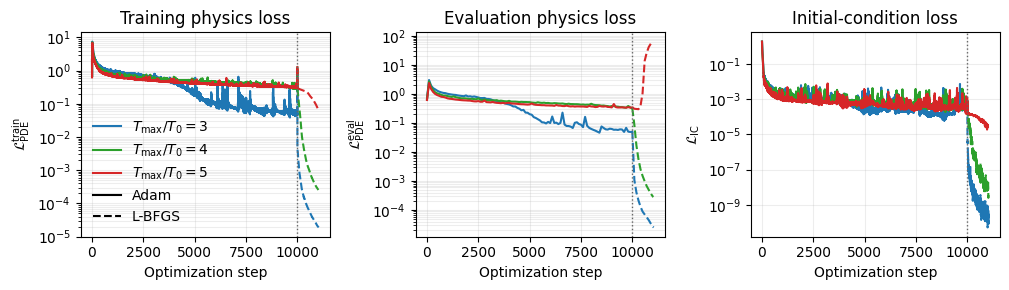

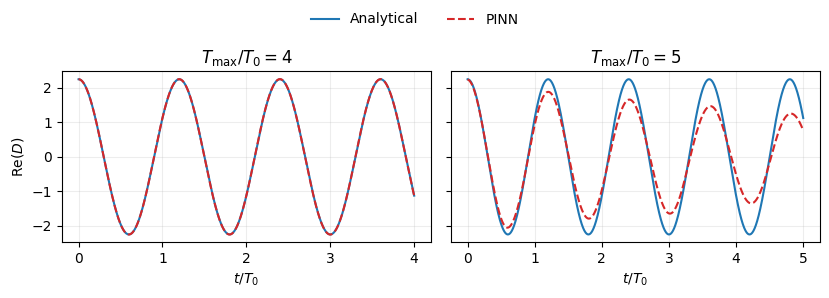

In [ ]:
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
run_metrics_df = pd.DataFrame(run_metrics)


def read_saved_csv(saved_path, fallback_dir):
    path = Path(saved_path)
    if not path.exists():
        path = fallback_dir / path.name
    return pd.read_csv(path)


def optimizer_curve(history, loss_column):
    adam = history[history["stage"].astype(str).isin(["Adam", "Adam final"])].copy()
    adam = adam[np.isfinite(adam[loss_column])]
    lbfgs = history[history["stage"].astype(str).str.startswith("L-BFGS")].copy()
    lbfgs = lbfgs[np.isfinite(lbfgs[loss_column])]
    adam_end = adam["step"].max()
    return (
        adam["step"].to_numpy(), adam[loss_column].to_numpy(),
        adam_end + lbfgs["step"].to_numpy(), lbfgs[loss_column].to_numpy(),
    )


# Figure 2
WINDOWS_FIGURE_2 = [3.0, 4.0, 5.0]
COLORS = {3.0: "tab:blue", 4.0: "tab:green", 5.0: "tab:red"}
loss_specs = [
    ("physics_train_loss", r"$\mathcal{L}_{\rm PDE}^{\rm train}$", "Training physics loss"),
    ("physics_eval_loss", r"$\mathcal{L}_{\rm PDE}^{\rm eval}$", "Evaluation physics loss"),
    ("initial_loss", r"$\mathcal{L}_{\rm IC}$", "Initial-condition loss"),
]

fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.0), sharex=True)
for ax, (loss_column, ylabel, title) in zip(axes, loss_specs):
    for tau_max in WINDOWS_FIGURE_2:
        subset = run_metrics_df[
            (run_metrics_df["config_name"] == "tanh")
            & np.isclose(run_metrics_df["n2"], 1.8)
            & np.isclose(run_metrics_df["tau_max"], tau_max)
        ]
        curves = [
            optimizer_curve(
                read_saved_csv(run["loss_history_file"], LOSS_DIR), loss_column
            )
            for _, run in subset.iterrows()
        ]
        adam_len = min(len(curve[1]) for curve in curves)
        lbfgs_len = min(len(curve[3]) for curve in curves)
        ax.semilogy(
            curves[0][0][:adam_len],
            np.vstack([curve[1][:adam_len] for curve in curves]).mean(axis=0),
            color=COLORS[tau_max], label=rf"$T_{{\max}}/T_0={tau_max:g}$",
        )
        ax.semilogy(
            curves[0][2][:lbfgs_len],
            np.vstack([curve[3][:lbfgs_len] for curve in curves]).mean(axis=0),
            color=COLORS[tau_max], linestyle="--",
        )
    ax.axvline(ADAM_EPOCHS, color="0.4", linestyle=":", linewidth=1.0)
    ax.set_title(title)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", alpha=0.22)

axes[0].plot([], [], color="black", label="Adam")
axes[0].plot([], [], color="black", linestyle="--", label="L-BFGS")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_2.pdf", bbox_inches="tight")
fig.savefig(FIGURES_DIR / "figure_2.png", dpi=300, bbox_inches="tight")
plt.show()


# Figure 3
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.0), sharey=True)
for ax, tau_max in zip(axes, [4.0, 5.0]):
    subset = run_metrics_df[
        (run_metrics_df["config_name"] == "tanh")
        & np.isclose(run_metrics_df["n2"], 1.8)
        & np.isclose(run_metrics_df["tau_max"], tau_max)
    ]
    median_error = subset["relative_l2_D"].median()
    representative = subset.loc[
        (subset["relative_l2_D"] - median_error).abs().idxmin()
    ]
    prediction = read_saved_csv(representative["prediction_file"], PREDICTIONS_DIR)
    ax.plot(prediction["tau"], prediction["D_true_real"], label="Analytical")
    ax.plot(
        prediction["tau"], prediction["D_pred_real"],
        color="tab:red", linestyle="--", label="PINN",
    )
    ax.set_title(rf"$T_{{\max}}/T_0={tau_max:g}$")
    ax.set_xlabel(r"$t/T_0$")
    ax.grid(True, alpha=0.22)
axes[0].set_ylabel(r"Re$(D)$")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(FIGURES_DIR / "figure_3.pdf", bbox_inches="tight")
fig.savefig(FIGURES_DIR / "figure_3.png", dpi=300, bbox_inches="tight")
plt.show()
